# Rendimiento de Búsqueda Tabú en el problema de las N Reinas

Este notebook importa `reynas_tabu.py`, prueba el algoritmo con **estados iniciales aleatorios** y mide las métricas exigidas: **tiempo de ejecución** y **cantidad de movimientos**. También compara contra una escalada simple (sin lista tabú) y estudia el efecto de la tenencia tabú y del tamaño del tablero.

Contenido:
1. Ejecución demostrativa con un estado aleatorio
2. Experimento con miles de estados iniciales (n = 8)
3. Efecto de la tenencia tabú
4. Búsqueda Tabú vs. escalada simple
5. Escalamiento con el tamaño del tablero
6. Función para el ejercicio de rendimiento en clase

In [4]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from reynas_tabu2 import (
    busqueda_tabu, escalada_simple, estado_aleatorio,
    funcion_objetivo, Resultado
)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# Parámetros del experimento
N = 8              # número de reinas
TENENCIA = 5       # tenencia tabú por defecto
MAX_ITER = 1000    # criterio de parada de respaldo
REPETICIONES = 2000

## 1. Ejecución demostrativa con un estado aleatorio

No se fija semilla, así que cada vez que se ejecuta la celda el estado inicial es distinto (requisito de la actividad). Las reinas en conflicto se dibujan en rojo.

Estado inicial: [1, 4, 8, 3, 7, 5, 2, 6] -> f = 3
Estado final  : [7, 2, 4, 1, 8, 5, 3, 6] -> f = 0
Éxito: True | Movimientos: 5 | Evaluaciones: 141 | Tiempo: 0.341 ms


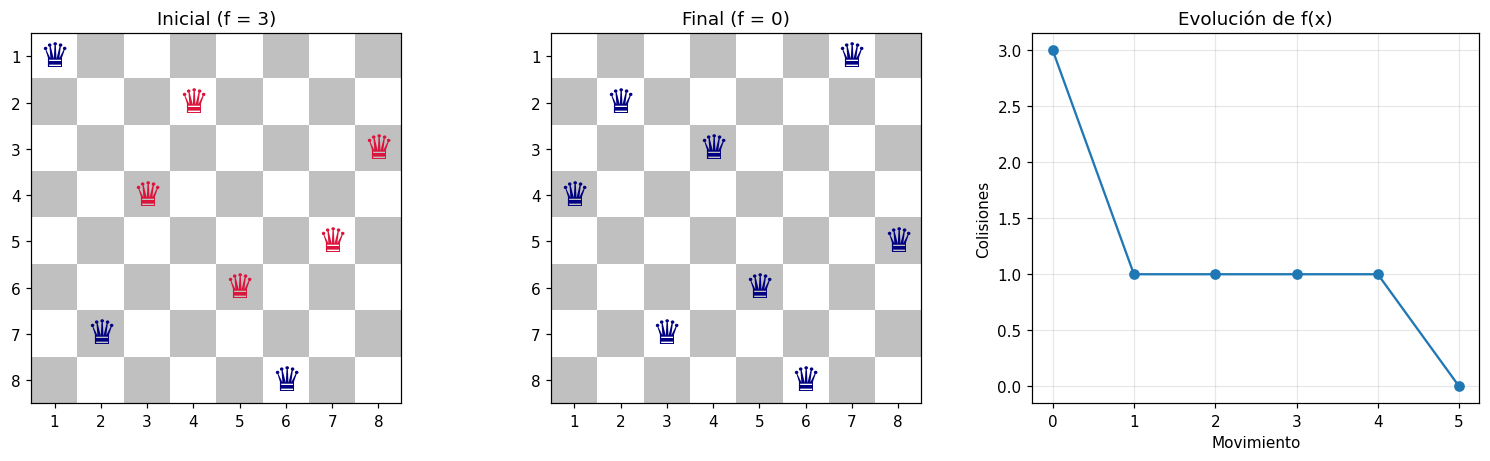

In [8]:
def reinas_en_conflicto(estado):
    """Índices de las filas cuyas reinas colisionan en diagonal con alguna otra."""
    n = len(estado)
    conflicto = set()
    for i in range(n - 1):
        for j in range(i + 1, n):
            if abs(i - j) == abs(estado[i] - estado[j]):
                conflicto.update((i, j))
    return conflicto


def dibujar_tablero(ax, estado, titulo):
    n = len(estado)
    tablero = np.add.outer(np.arange(n), np.arange(n)) % 2
    ax.imshow(tablero, cmap="Greys", alpha=0.25)
    malas = reinas_en_conflicto(estado)
    for fila, col in enumerate(estado):
        ax.text(col - 1, fila, "♛", ha="center", va="center", fontsize=22,
                color="crimson" if fila in malas else "navy")
    ax.set_xticks(range(n)); ax.set_xticklabels(range(1, n + 1))
    ax.set_yticks(range(n)); ax.set_yticklabels(range(1, n + 1))
    ax.grid(False)
    ax.set_title(titulo)


x0 = estado_aleatorio(N)
r = busqueda_tabu(estado_inicial=x0, tenencia=TENENCIA, max_iteraciones=MAX_ITER)

print("Estado inicial:", r.estado_inicial, "-> f =", funcion_objetivo(r.estado_inicial))
print("Estado final  :", r.mejor_estado, "-> f =", r.mejor_f)
print(f"Éxito: {r.exito} | Movimientos: {r.movimientos} | "
      f"Evaluaciones: {r.evaluaciones} | Tiempo: {r.tiempo * 1000:.3f} ms")

fig, axs = plt.subplots(1, 3, figsize=(14, 4.3))
dibujar_tablero(axs[0], r.estado_inicial, f"Inicial (f = {r.historial[0]})")
dibujar_tablero(axs[1], r.mejor_estado, f"Final (f = {r.mejor_f})")
axs[2].plot(r.historial, marker="o")
axs[2].set_title("Evolución de f(x)")
axs[2].set_xlabel("Movimiento")
axs[2].set_ylabel("Colisiones")
plt.tight_layout()
plt.show()

## 2. Experimento con miles de estados iniciales (n = 8)

Cada repetición usa una semilla distinta, que determina el estado inicial aleatorio y los desempates. Como la semilla define el mismo estado inicial para Búsqueda Tabú y para la escalada simple, la comparación de la sección 4 es **pareada** (ambos arrancan desde los mismos estados).

In [11]:
def correr(algoritmo, repeticiones, **kwargs):
    """Ejecuta el algoritmo con semillas 0..repeticiones-1 y devuelve un DataFrame."""
    filas = []
    for semilla in range(repeticiones):
        r = algoritmo(semilla=semilla, **kwargs)
        filas.append({
            "semilla": semilla,
            "f_inicial": r.historial[0],
            "exito": r.exito,
            "f_final": r.mejor_f,
            "movimientos": r.movimientos,
            "evaluaciones": r.evaluaciones,
            "tiempo_ms": r.tiempo * 1000,
        })
    return pd.DataFrame(filas)


df_tabu = correr(busqueda_tabu, REPETICIONES, n=N, tenencia=TENENCIA, max_iteraciones=MAX_ITER)

print(f"Tasa de éxito: {df_tabu['exito'].mean():.1%}  ({df_tabu['exito'].sum()} de {len(df_tabu)})")

resumen = df_tabu[["movimientos", "evaluaciones", "tiempo_ms"]].agg(
    ["mean", "median", "std", "min", "max"]
).T
resumen["p95"] = df_tabu[["movimientos", "evaluaciones", "tiempo_ms"]].quantile(0.95)
resumen.round(3)

Tasa de éxito: 100.0%  (2000 de 2000)


,mean,median,std,min,max,p95
movimientos,4.180,3.0,2.550,0.000,20.00,9.000
evaluaciones,118.040,85.0,71.407,1.000,561.00,253.000
tiempo_ms,0.364,0.3,0.231,0.003,2.08,0.818


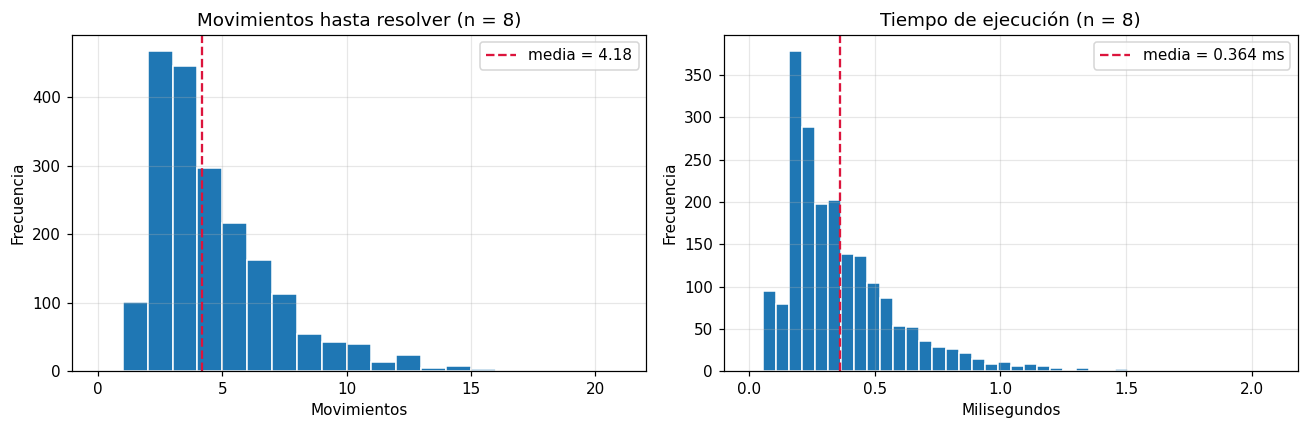

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

max_mov = int(df_tabu["movimientos"].max())
axs[0].hist(df_tabu["movimientos"], bins=range(0, max_mov + 2), edgecolor="white")
axs[0].axvline(df_tabu["movimientos"].mean(), color="crimson", linestyle="--",
               label=f"media = {df_tabu['movimientos'].mean():.2f}")
axs[0].set_title("Movimientos hasta resolver (n = 8)")
axs[0].set_xlabel("Movimientos"); axs[0].set_ylabel("Frecuencia"); axs[0].legend()

axs[1].hist(df_tabu["tiempo_ms"], bins=40, edgecolor="white")
axs[1].axvline(df_tabu["tiempo_ms"].mean(), color="crimson", linestyle="--",
               label=f"media = {df_tabu['tiempo_ms'].mean():.3f} ms")
axs[1].set_title("Tiempo de ejecución (n = 8)")
axs[1].set_xlabel("Milisegundos"); axs[1].set_ylabel("Frecuencia"); axs[1].legend()

plt.tight_layout()
plt.show()

In [13]:
# ¿Depende la dificultad de qué tan malo es el estado inicial?
df_tabu.groupby("f_inicial")["movimientos"].agg(["count", "mean", "max"]).round(2)

,count,mean,max
f_inicial,,,
0,2,0.00,0
1,42,3.14,8
2,137,2.99,15
3,316,3.66,16
4,413,4.06,14
5,378,4.42,17
6,284,4.69,20
7,176,4.36,17
8,127,4.51,12


## 3. Efecto de la tenencia tabú

Se repite el experimento variando la tenencia. Con 8 reinas el espacio es muy pequeño (40 320 estados), por lo que se espera poca diferencia; la sección 5 muestra qué pasa con tableros mayores.

          exito_%  mov_media  mov_p95  mov_max  tiempo_ms_medio
tenencia                                                       
1           100.0      4.292     10.0       20            0.331
3           100.0      4.232     10.0       16            0.326
5           100.0      4.270     10.0       20            0.325
7           100.0      4.294     10.0       19            0.319
10          100.0      4.250     10.0       15            0.339
15          100.0      4.250     10.0       15            0.317
20          100.0      4.250     10.0       15            0.326


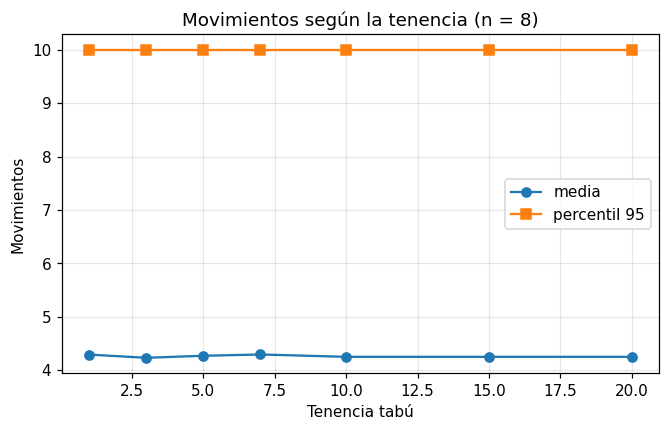

In [14]:
tenencias = [1, 3, 5, 7, 10, 15, 20]
filas = []
for t in tenencias:
    d = correr(busqueda_tabu, 500, n=N, tenencia=t, max_iteraciones=MAX_ITER)
    filas.append({
        "tenencia": t,
        "exito_%": 100 * d["exito"].mean(),
        "mov_media": d["movimientos"].mean(),
        "mov_p95": d["movimientos"].quantile(0.95),
        "mov_max": d["movimientos"].max(),
        "tiempo_ms_medio": d["tiempo_ms"].mean(),
    })
df_tenencia = pd.DataFrame(filas).set_index("tenencia")

print(df_tenencia.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(df_tenencia.index, df_tenencia["mov_media"], marker="o", label="media")
ax.plot(df_tenencia.index, df_tenencia["mov_p95"], marker="s", label="percentil 95")
ax.set_xlabel("Tenencia tabú"); ax.set_ylabel("Movimientos")
ax.set_title("Movimientos según la tenencia (n = 8)"); ax.legend()
plt.show()

## 4. Búsqueda Tabú vs. escalada simple

La escalada simple se mueve al mejor vecino mientras mejore y se detiene en el primer óptimo local. Es la misma búsqueda sin memoria ni aceptación de movimientos que empeoran, así que aísla el aporte de la lista tabú.

                     Búsqueda Tabú  Escalada simple
éxito (%)                  100.000           45.050
movimientos (media)          4.180            1.920
tiempo medio (ms)            0.364            0.168


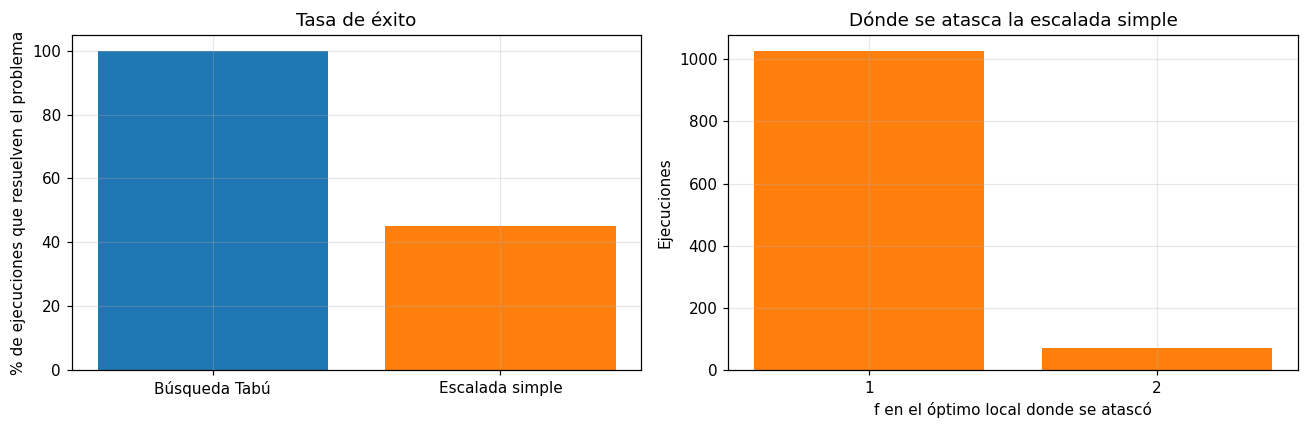

In [15]:
df_esc = correr(escalada_simple, REPETICIONES, n=N, max_iteraciones=MAX_ITER)

comparacion = pd.DataFrame({
    "Búsqueda Tabú": {
        "éxito (%)": 100 * df_tabu["exito"].mean(),
        "movimientos (media)": df_tabu["movimientos"].mean(),
        "tiempo medio (ms)": df_tabu["tiempo_ms"].mean(),
    },
    "Escalada simple": {
        "éxito (%)": 100 * df_esc["exito"].mean(),
        "movimientos (media)": df_esc["movimientos"].mean(),
        "tiempo medio (ms)": df_esc["tiempo_ms"].mean(),
    },
}).round(3)
print(comparacion)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].bar(["Búsqueda Tabú", "Escalada simple"],
           [100 * df_tabu["exito"].mean(), 100 * df_esc["exito"].mean()],
           color=["tab:blue", "tab:orange"])
axs[0].set_ylabel("% de ejecuciones que resuelven el problema")
axs[0].set_title("Tasa de éxito"); axs[0].set_ylim(0, 105)

fallos = df_esc[~df_esc["exito"]]["f_final"].value_counts().sort_index()
axs[1].bar(fallos.index.astype(str), fallos.values, color="tab:orange")
axs[1].set_xlabel("f en el óptimo local donde se atascó"); axs[1].set_ylabel("Ejecuciones")
axs[1].set_title("Dónde se atasca la escalada simple")
plt.tight_layout()
plt.show()

## 5. Escalamiento con el tamaño del tablero

Se aumenta *n* para ver cómo crecen los movimientos y, sobre todo, el tiempo. Cada iteración evalúa n(n−1)/2 vecinos y cada evaluación cuesta O(n²), por lo que se espera un crecimiento del tiempo por iteración de orden O(n⁴) (ver sección 5.4 de `documentation.md`).

    exito_%  mov_media  evaluaciones_media  tiempo_ms_medio
n                                                          
8     100.0       4.60              129.80             0.33
10    100.0       6.86              309.70             1.08
12    100.0       6.70              443.20             2.19
16    100.0       8.34             1001.80             9.26
20    100.0       8.88             1688.20            24.84
24    100.0       9.18             2534.68            50.60


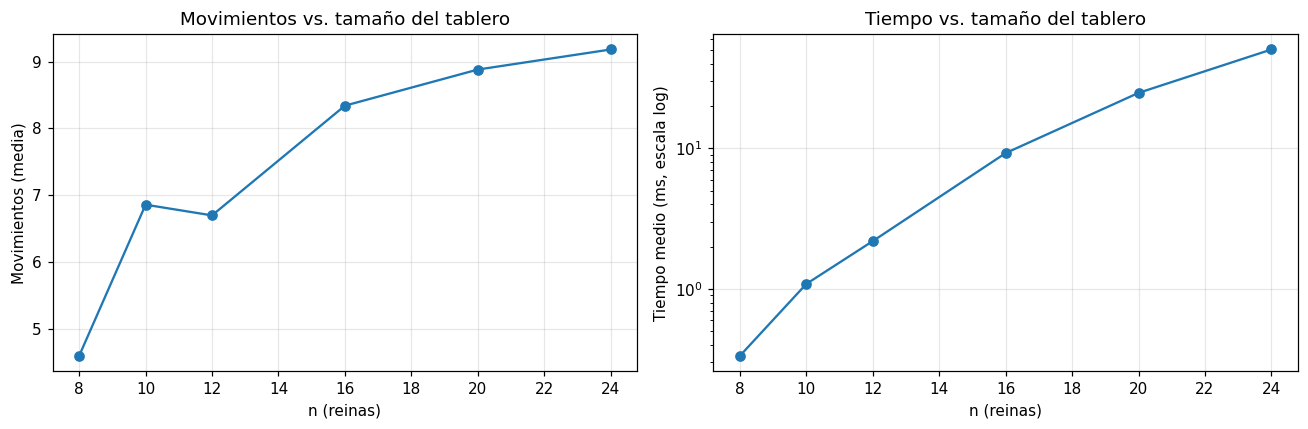

In [16]:
tamanos = [8, 10, 12, 16, 20, 24]
filas = []
for n in tamanos:
    d = correr(busqueda_tabu, 50, n=n, tenencia=5, max_iteraciones=2000)
    filas.append({
        "n": n,
        "exito_%": 100 * d["exito"].mean(),
        "mov_media": d["movimientos"].mean(),
        "evaluaciones_media": d["evaluaciones"].mean(),
        "tiempo_ms_medio": d["tiempo_ms"].mean(),
    })
df_n = pd.DataFrame(filas).set_index("n")
print(df_n.round(2))

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(df_n.index, df_n["mov_media"], marker="o")
axs[0].set_xlabel("n (reinas)"); axs[0].set_ylabel("Movimientos (media)")
axs[0].set_title("Movimientos vs. tamaño del tablero")

axs[1].semilogy(df_n.index, df_n["tiempo_ms_medio"], marker="o")
axs[1].set_xlabel("n (reinas)"); axs[1].set_ylabel("Tiempo medio (ms, escala log)")
axs[1].set_title("Tiempo vs. tamaño del tablero")
plt.tight_layout()
plt.show()

## 6. Ejercicio de rendimiento en clase

La función ejecuta el algoritmo sobre un estado aleatorio nuevo (o uno dado) y reporta las métricas pedidas.

In [17]:
def ejercicio_clase(n=8, tenencia=5, max_iteraciones=1000, estado_inicial=None):
    """Corre Búsqueda Tabú sobre un estado aleatorio y muestra las métricas."""
    r = busqueda_tabu(estado_inicial=estado_inicial, n=n, tenencia=tenencia, max_iteraciones=max_iteraciones)
    print("Estado inicial :", r.estado_inicial, f"(f = {r.historial[0]})")
    print("Estado final   :", r.mejor_estado, f"(f = {r.mejor_f})")
    print("¿Resuelto?     :", "Sí" if r.exito else "No")
    print("Movimientos    :", r.movimientos)
    print("Evaluaciones   :", r.evaluaciones)
    print(f"Tiempo         : {r.tiempo * 1000:.3f} ms")
    print()
    print(tablero_texto(r.mejor_estado))
    return r


_ = ejercicio_clase()

Estado inicial : [3, 2, 8, 1, 7, 4, 6, 5] (f = 4)
Estado final   : [5, 2, 6, 1, 7, 4, 8, 3] (f = 0)
¿Resuelto?     : Sí
Movimientos    : 2
Evaluaciones   : 57
Tiempo         : 0.189 ms

. . . . R . . .
. R . . . . . .
. . . . . R . .
R . . . . . . .
. . . . . . R .
. . . R . . . .
. . . . . . . R
. . R . . . . .


## Conclusiones

Completa esta sección con los resultados de **tu** ejecución (los valores cambian un poco entre máquinas, sobre todo el tiempo):

- **Rendimiento con n = 8:** ¿qué tasa de éxito y cuántos movimientos medios y máximos se obtuvieron? ¿Y el tiempo medio?
- **Tenencia tabú:** ¿cambió algo al variarla con n = 8? ¿Por qué crees que pasa (tamaño del espacio y densidad de soluciones)?
- **Tabú vs. escalada:** ¿qué porcentaje resolvió la escalada simple y en qué valores de f se atascó? ¿Qué aporta la lista tabú?
- **Escalamiento:** ¿cómo crecen los movimientos y el tiempo con n? ¿Concuerda con el análisis de complejidad de `documentation.md`?
- **Limitaciones:** la evaluación de f recalcula todos los pares en cada vecino (O(n²)); una evaluación incremental reduciría el costo por iteración.